In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

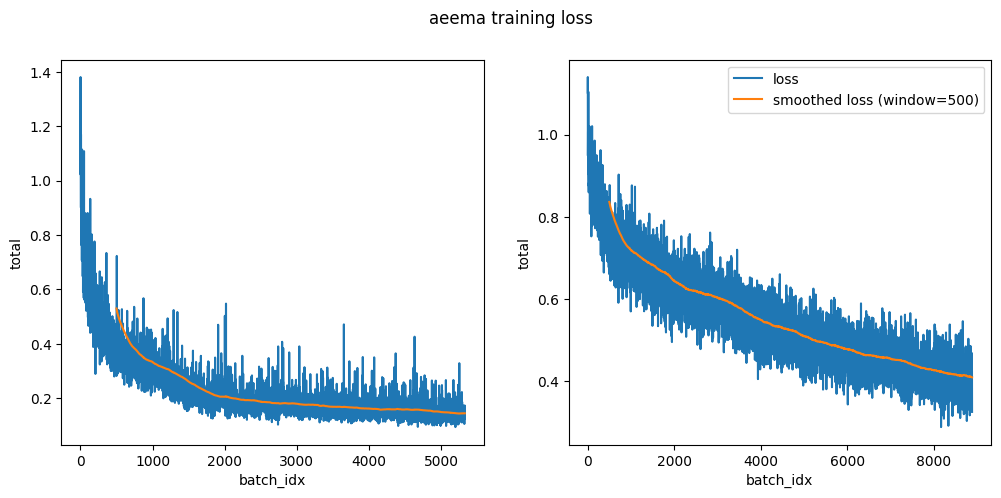

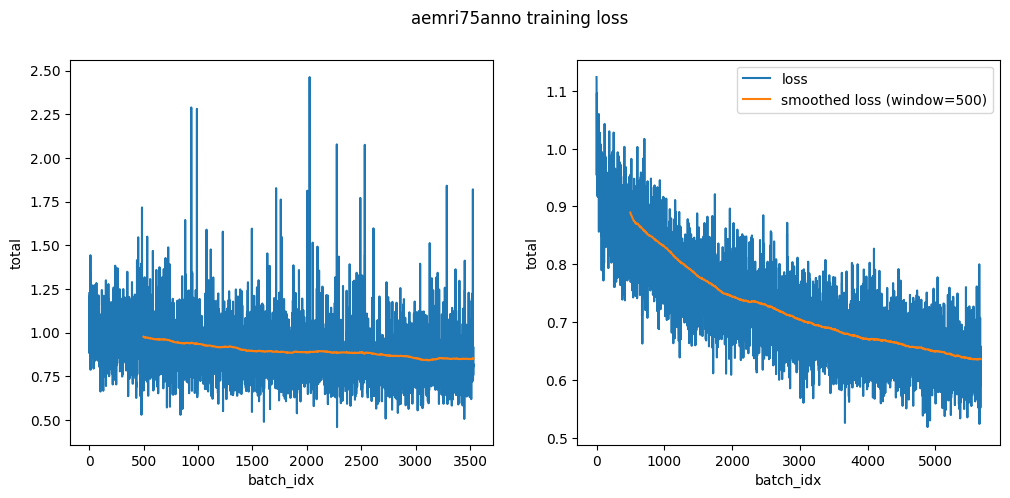

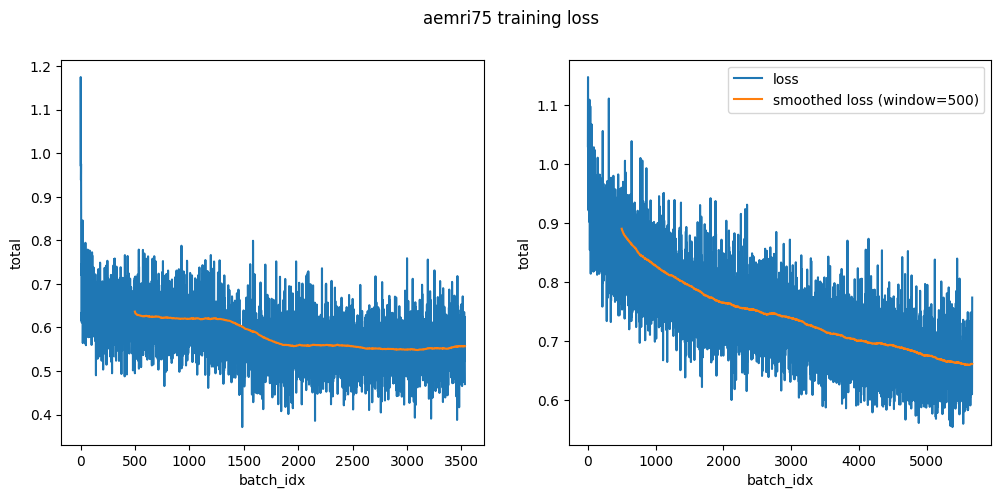

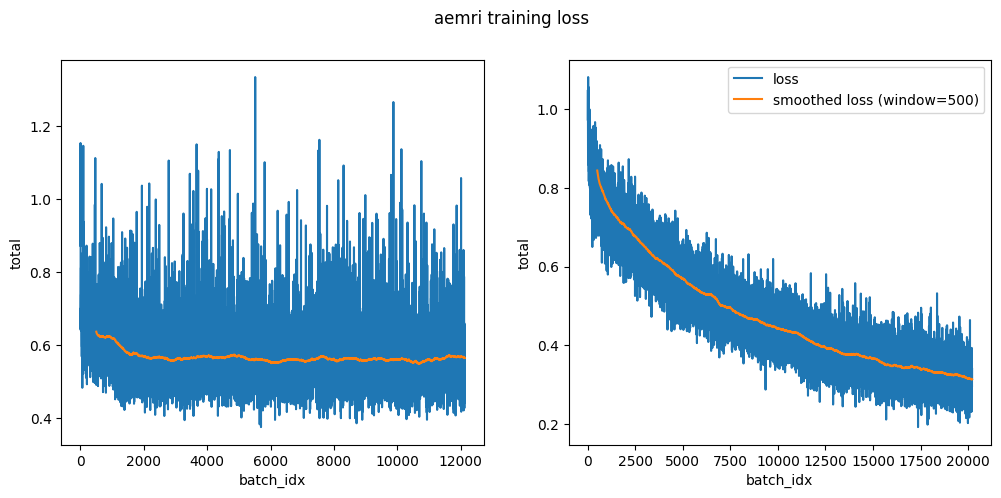

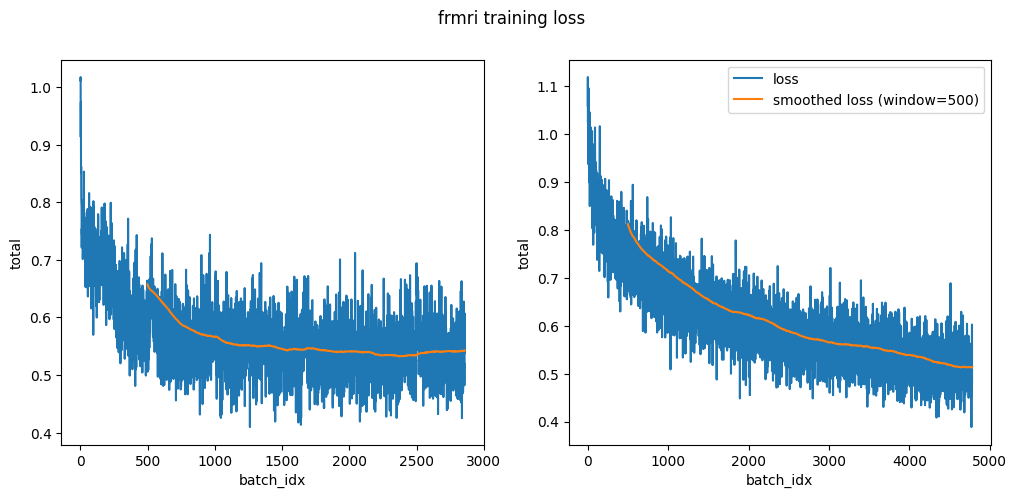

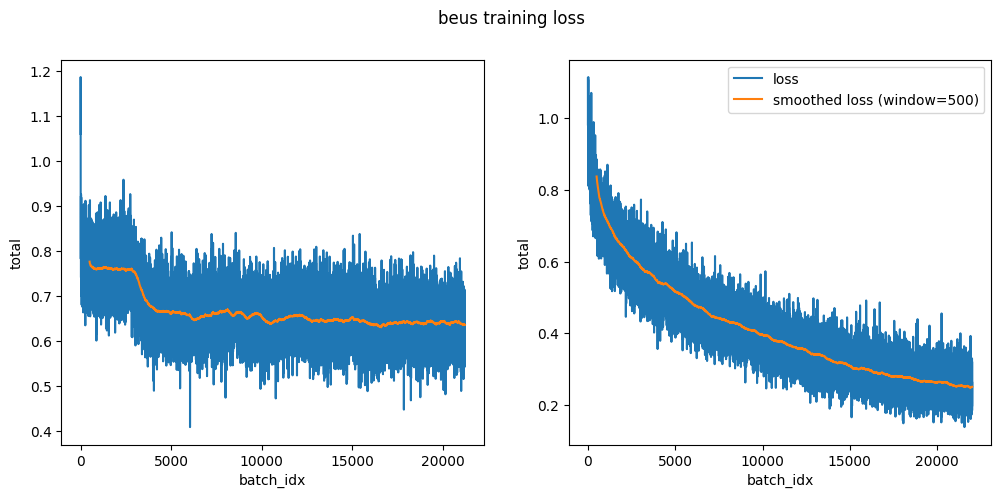

In [24]:
window_size = 500
for dataset_name in ["aeema", "aemri75anno", "aemri75", "aemri", "frmri", "beus"]:
    if not os.path.exists(f"{dataset_name}/art_model_training_log.csv"): continue
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"{dataset_name} training loss")

    df = pd.read_csv(f"{dataset_name}/art_model_training_log.csv")
    df["batch_idx"] = df.index
    sns.lineplot(data=df, x="batch_idx", y="total", ax=axs[0])
    df["smoothed_loss"] = df["total"].rolling(window=window_size).mean()
    sns.lineplot(data=df, x="batch_idx", y="smoothed_loss", ax=axs[0])

    if not os.path.exists(f"{dataset_name}/ac_model_training_log.csv"): continue
    df = pd.read_csv(f"{dataset_name}/ac_model_training_log.csv")
    df["batch_idx"] = df.index
    sns.lineplot(data=df, x="batch_idx", y="total", ax=axs[1], label="loss")
    df["smoothed_loss"] = df["total"].rolling(window=window_size).mean()
    sns.lineplot(data=df, x="batch_idx", y="smoothed_loss", ax=axs[1], label=f"smoothed loss (window={window_size})")
    plt.show()

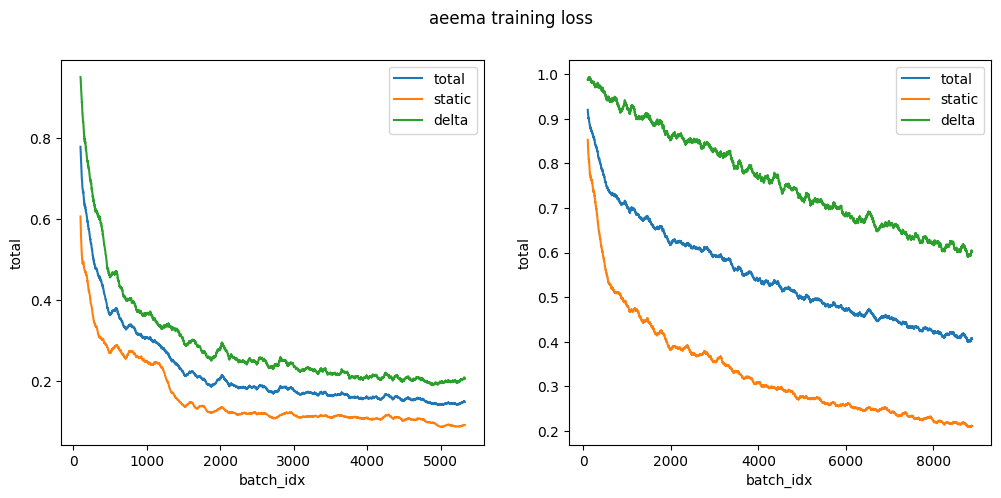

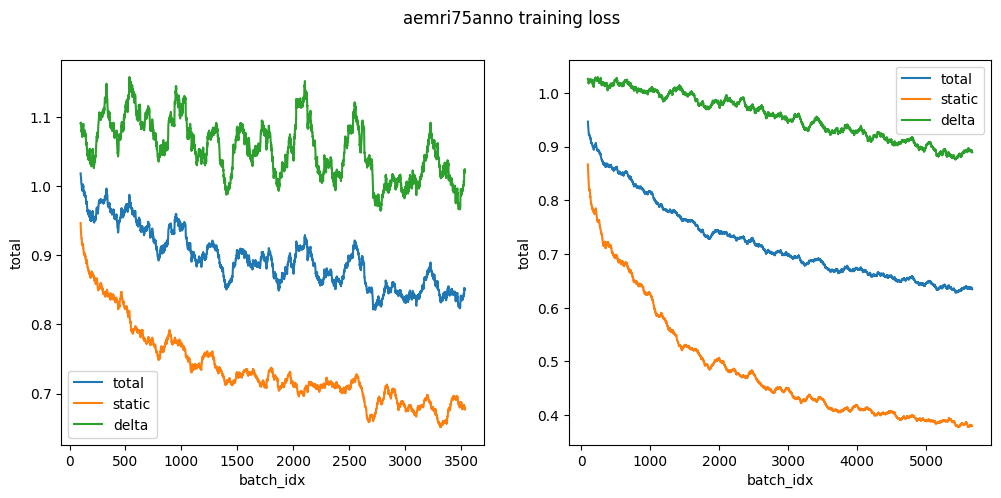

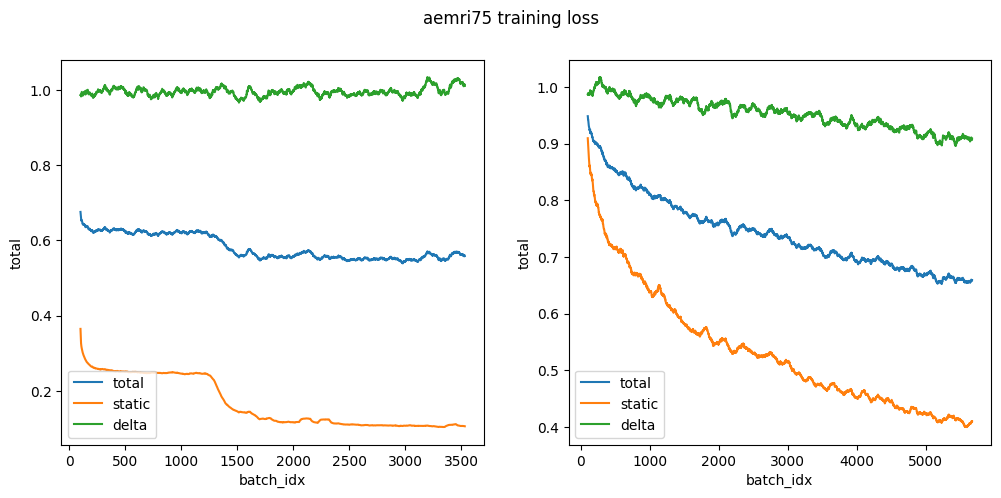

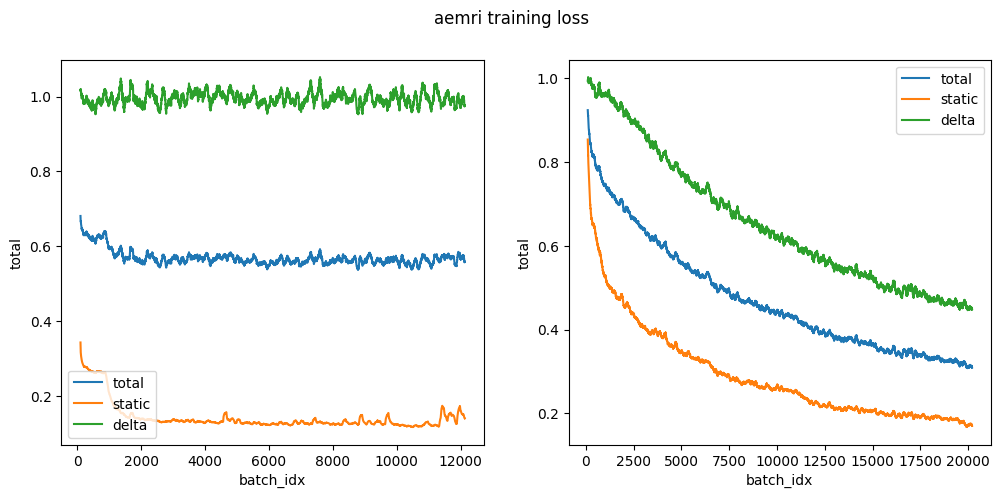

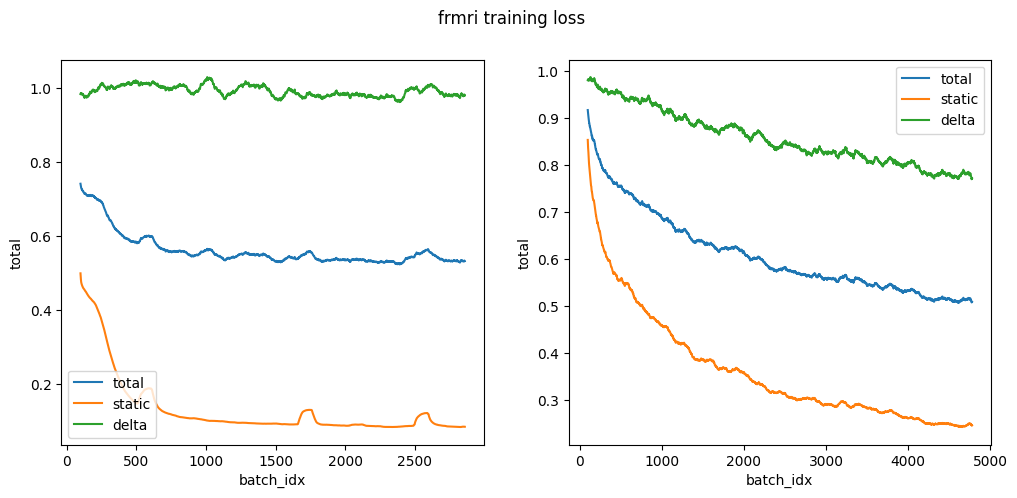

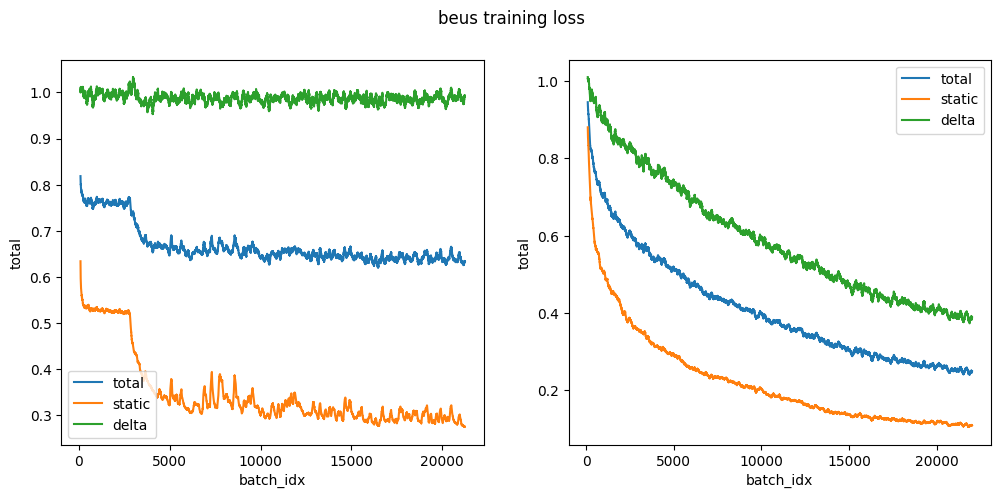

In [25]:
window_size = 100
loss_types = ["total", "static", "delta"]
for dataset_name in ["aeema", "aemri75anno", "aemri75", "aemri", "frmri", "beus"]:
    if not os.path.exists(f"{dataset_name}/art_model_training_log.csv"): continue
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"{dataset_name} training loss")

    df = pd.read_csv(f"{dataset_name}/art_model_training_log.csv")
    df["batch_idx"] = df.index
    for loss_type in loss_types:
        df[loss_type] = df[loss_type].rolling(window=window_size).mean()
        sns.lineplot(data=df, x="batch_idx", y=loss_type, ax=axs[0], label=loss_type)

    if not os.path.exists(f"{dataset_name}/ac_model_training_log.csv"): continue
    df = pd.read_csv(f"{dataset_name}/ac_model_training_log.csv")
    df["batch_idx"] = df.index
    for loss_type in loss_types:
        df[loss_type] = df[loss_type].rolling(window=window_size).mean()
        sns.lineplot(data=df, x="batch_idx", y=loss_type, ax=axs[1], label=loss_type)
    plt.show()